In [1]:
import pandas as pd, matplotlib.pyplot as plt, scipy.stats as stats

# ---------------------------------------------------------------
# STEP 1: Load and profile the raw file
# ---------------------------------------------------------------
df = pd.read_csv("../data/meridian_churn_data.csv")

print("Shape:", df.shape)
print("Duplicate customer_id count:", df["customer_id"].duplicated().sum())
print("Fully blank rows:", df.isna().all(axis=1).sum())
print("\nMissing values per column:\n", df.isna().sum())

Shape: (1400, 14)
Duplicate customer_id count: 0
Fully blank rows: 0

Missing values per column:
 customer_id                          0
segment                              0
plan_tier                            0
monthly_price                        0
tenure_months                        0
signup_channel                       0
support_tickets_last_90d             0
avg_support_response_hours           0
product_usage_score                  0
num_users_licensed                   0
num_users_active                     0
had_price_increase_last_quarter      0
nps_score                          380
churned                              0
dtype: int64


In [2]:
# STEP 2: Check each numeric column's range for implausible values
# ---------------------------------------------------------------
print("\nmonthly_price range:", df["monthly_price"].min(), "to", df["monthly_price"].max())
neg_price_rows = df[df["monthly_price"] < 0]
print("Negative price rows found:", len(neg_price_rows))
print(neg_price_rows[["customer_id", "segment", "plan_tier", "monthly_price"]])


monthly_price range: -517.9 to 573.7
Negative price rows found: 3
    customer_id     segment   plan_tier  monthly_price
156     C100156  Enterprise  Enterprise        -517.90
478     C100478         SMB       Basic         -46.62
609     C100609         SMB       Basic         -55.22


In [3]:
# STEP 3: Diagnose the negative prices
# Compare each negative value's absolute size to its plan tier's
# typical (median) price to confirm it's a sign-flip, not a real
# credit/refund.
# ---------------------------------------------------------------
for idx, row in neg_price_rows.iterrows():
    plan_median = df.loc[df["plan_tier"] == row["plan_tier"], "monthly_price"].abs().median()
    print(
        f"{row['customer_id']} ({row['plan_tier']}): "
        f"raw={row['monthly_price']}, abs={abs(row['monthly_price'])}, "
        f"plan median={plan_median:.2f}"
    )

C100156 (Enterprise): raw=-517.9, abs=517.9, plan median=510.90
C100478 (Basic): raw=-46.62, abs=46.62, plan median=50.48
C100609 (Basic): raw=-55.22, abs=55.22, plan median=50.48


In [4]:
# STEP 4: Correct the sign (keep the rows, don't drop them)
# ---------------------------------------------------------------
df["monthly_price"] = df["monthly_price"].abs()
assert (df["monthly_price"] < 0).sum() == 0, "Negative prices remain after cleaning"
print("monthly_price range:", df["monthly_price"].min(), "to", df["monthly_price"].max())

monthly_price range: 44.13 to 573.7


In [5]:
# STEP 5: Check nps_score missingness
# ---------------------------------------------------------------
missing_nps = df["nps_score"].isna().sum()
print(f"\nnps_score missing: {missing_nps} of {len(df)} ({missing_nps/len(df):.1%})")


nps_score missing: 380 of 1400 (27.1%)


In [6]:
# STEP 6: Flag non-response instead of imputing a fake score
# ---------------------------------------------------------------
df["nps_responded"] = df["nps_score"].notna()

In [7]:
# STEP 7: Add derived column — seat utilization
# ---------------------------------------------------------------
df["seat_utilization"] = df["num_users_active"] / df["num_users_licensed"]

In [8]:
# STEP 8: Re-check logical consistency after cleaning
checks = {
    "active seats > licensed seats": (df["num_users_active"] > df["num_users_licensed"]).sum(),
    "negative tenure_months": (df["tenure_months"] < 0).sum(),
    "usage_score out of 0-100 range": (~df["product_usage_score"].between(0, 100)).sum(),
    "nps_score out of -100..100 range": (~df["nps_score"].between(-100, 100) & df["nps_score"].notna()).sum(),
    "negative monthly_price remaining": (df["monthly_price"] < 0).sum(),
}
print("\nPost-clean consistency checks (should all be 0):")
for check, count in checks.items():
    print(f"  {check}: {count}")


Post-clean consistency checks (should all be 0):
  active seats > licensed seats: 0
  negative tenure_months: 0
  usage_score out of 0-100 range: 0
  nps_score out of -100..100 range: 0
  negative monthly_price remaining: 0


## Monthly Price vs Churned

In [9]:
df

,customer_id,segment,plan_tier,monthly_price,tenure_months,signup_channel,support_tickets_last_90d,avg_support_response_hours,product_usage_score,num_users_licensed,num_users_active,had_price_increase_last_quarter,nps_score,churned,nps_responded,seat_utilization
0,C100000,SMB,Basic,48.51,30,Organic,6,5.0,79.0,27,17,False,38.0,False,True,0.629630
1,C100001,SMB,Basic,50.78,8,Partner,4,1.9,66.9,6,4,True,34.0,False,True,0.666667
2,C100002,Enterprise,Enterprise,527.79,15,Outbound Sales,5,8.1,70.9,72,45,False,NaN,False,False,0.625000
3,C100003,SMB,Pro,142.67,38,Organic,2,1.8,43.0,13,5,False,32.0,True,True,0.384615
4,C100004,Enterprise,Enterprise,458.53,15,Paid Search,4,9.3,64.6,306,144,False,20.0,True,True,0.470588
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1395,C101395,SMB,Pro,158.19,46,Organic,9,6.2,25.2,16,3,True,NaN,True,False,0.187500
1396,C101396,SMB,Basic,47.98,14,Partner,3,2.0,30.2,4,1,False,NaN,False,False,0.250000
1397,C101397,SMB,Pro,167.50,1,Organic,4,4.1,29.8,3,1,True,NaN,False,False,0.333333
1398,C101398,SMB,Basic,46.44,45,Organic,2,0.9,90.3,5,4,False,42.0,False,True,0.800000


In [11]:
import pandas as pd
import scipy.stats as stats

# Define features to test
features = [
    "segment",
    "plan_tier",
    "monthly_price",
    "tenure_months",
    "signup_channel",
    "support_tickets_last_90d",
    "avg_support_response_hours",
    "product_usage_score",
    "num_users_licensed",
    "num_users_active",
    "had_price_increase_last_quarter",
    "nps_score",
    "nps_responded",
    "seat_utilization"
]

# Ensure churned is 0 or 1
df['churned'] = df['churned'].astype(int)

significant_features = []
non_significant_features = []

print("=== Statistical Significance Test Results (Alpha = 0.05) ===\n")

for col in features:
    if col not in df.columns:
        print(f"Column [{col}] not found in DataFrame. Skipping.")
        continue

    # 1. Determine variable type: categorical (object, bool, or low cardinality) vs continuous
    if df[col].dtype == 'object' or df[col].dtype == 'bool' or df[col].nunique() <= 3:
        # Chi-Square test of independence
        contingency_table = pd.crosstab(df[col], df['churned'])
        chi2, p_val, dof, expected = stats.chi2_contingency(contingency_table)
        test_name = "Chi-Square"
    else:
        # Two-sample independent t-test
        group_churn = df[df['churned'] == 1][col].dropna()
        group_no_churn = df[df['churned'] == 0][col].dropna()

        t_stat, p_val = stats.ttest_ind(group_churn, group_no_churn, equal_var=False)
        test_name = "t-test"

    is_sig = p_val < 0.05
    status = "Significant" if is_sig else "Non-Significant"
    print(f"Feature: {col:<32} | Method: {test_name:<12} | p-value: {p_val:.6f} | Result: {status}")

    if is_sig:
        significant_features.append((col, p_val))
    else:
        non_significant_features.append((col, p_val))

print("\n=========================================")
print("Features with NO Statistically Significant Association (p >= 0.05):")
if non_significant_features:
    for col, p in non_significant_features:
        print(f" - {col} (p-value = {p:.4f})")
else:
    print(" All features show statistical significance!")

=== Statistical Significance Test Results (Alpha = 0.05) ===

Feature: segment                          | Method: Chi-Square   | p-value: 0.616556 | Result: Non-Significant
Feature: plan_tier                        | Method: Chi-Square   | p-value: 0.680499 | Result: Non-Significant
Feature: monthly_price                    | Method: t-test       | p-value: 0.339369 | Result: Non-Significant
Feature: tenure_months                    | Method: t-test       | p-value: 0.094021 | Result: Non-Significant
Feature: signup_channel                   | Method: Chi-Square   | p-value: 0.433601 | Result: Non-Significant
Feature: support_tickets_last_90d         | Method: t-test       | p-value: 0.000000 | Result: Significant
Feature: avg_support_response_hours       | Method: t-test       | p-value: 0.000000 | Result: Significant
Feature: product_usage_score              | Method: t-test       | p-value: 0.000000 | Result: Significant
Feature: num_users_licensed               | Method: t-test    

In [12]:
import statsmodels.formula.api as smf

# Ensure 'churned' is an integer (0 or 1)
df['churned'] = df['churned'].astype(int)

# List of statistically significant variables
# support_tickets_last_90d, avg_support_response_hours, product_usage_score,
# num_users_active, had_price_increase_last_quarter, nps_score, seat_utilization

# Formula specifying main effects and pairwise interactions (* operator)
formula_interactions = (
    "churned ~ (support_tickets_last_90d + avg_support_response_hours + "
    "product_usage_score + num_users_active + C(had_price_increase_last_quarter) + "
    "nps_score + seat_utilization) ** 2"
)

# Fit the logistic regression model with interaction terms
print("Fitting logistic regression model with pairwise interactions...\n")
interaction_model = smf.logit(formula=formula_interactions, data=df)
interaction_result = interaction_model.fit(maxiter=100)

# Display the model summary
print(interaction_result.summary())

Fitting logistic regression model with pairwise interactions...

Optimization terminated successfully.
         Current function value: 0.486048
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:                churned   No. Observations:                 1020
Model:                          Logit   Df Residuals:                      991
Method:                           MLE   Df Model:                           28
Date:                Sun, 04 Oct 2026   Pseudo R-squ.:                  0.2396
Time:                        04:39:18   Log-Likelihood:                -495.77
converged:                       True   LL-Null:                       -651.98
Covariance Type:            nonrobust   LLR p-value:                 8.305e-50
                                                                            coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------

In [15]:
# Extract p-values and coefficients from the fitted interaction model
p_values = interaction_result.pvalues
coefficients = interaction_result.params

print("=== Pairwise Interaction Model: Statistical Significance Results ===\n")

significant_terms = []
non_significant_terms = []

for term, p_val in p_values.items():
    if term == 'Intercept':
        continue

    coef = coefficients[term]
    is_sig = p_val < 0.05

    term_info = {
        "term": term,
        "coef": coef,
        "p_value": p_val
    }

    if is_sig:
        significant_terms.append(term_info)
    else:
        non_significant_terms.append(term_info)

print("--- STATISTICALLY SIGNIFICANT TERMS (p < 0.05) ---")
if significant_terms:
    for item in significant_terms:
        print(f"{item['term']:<80} | coef: {item['coef']:.4f} | p-value: {item['p_value']:.6f}")
else:
    print("No terms are statistically significant.")

print("\n--- NON-SIGNIFICANT TERMS (p >= 0.05) ---")
if non_significant_terms:
    for item in non_significant_terms:
        print(f"{item['term']:<80} | coef: {item['coef']:.4f} | p-value: {item['p_value']:.6f}")
else:
    print("No non-significant terms.")

=== Pairwise Interaction Model: Statistical Significance Results ===

--- STATISTICALLY SIGNIFICANT TERMS (p < 0.05) ---
C(had_price_increase_last_quarter)[T.True]:nps_score                             | coef: 0.0273 | p-value: 0.045092

--- NON-SIGNIFICANT TERMS (p >= 0.05) ---
C(had_price_increase_last_quarter)[T.True]                                       | coef: -0.3431 | p-value: 0.612782
support_tickets_last_90d                                                         | coef: 0.2342 | p-value: 0.117697
support_tickets_last_90d:C(had_price_increase_last_quarter)[T.True]              | coef: 0.1119 | p-value: 0.213773
avg_support_response_hours                                                       | coef: -0.0323 | p-value: 0.716437
avg_support_response_hours:C(had_price_increase_last_quarter)[T.True]            | coef: 0.0341 | p-value: 0.455759
product_usage_score                                                              | coef: -0.0422 | p-value: 0.131016
product_usage_score:C

In [18]:
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf

# Continue with the cleaned frame built in the steps above.
# Do NOT reload the raw file here: that would silently undo the Step 4
# price sign correction for every cell that follows.

# Convert churned to numeric if needed
df["churned_num"] = df["churned"].astype(int)

# Create seat utilization
df["seat_utilization"] = (
    df["num_users_active"] / df["num_users_licensed"]
)

# Models: progressively add variables
models = {
    "Model 1: Price Increase Only":
        "churned_num ~ C(had_price_increase_last_quarter)",

    "Model 2: + Support Tickets":
        "churned_num ~ C(had_price_increase_last_quarter) "
        "+ support_tickets_last_90d",

    "Model 3: + Product Usage":
        "churned_num ~ C(had_price_increase_last_quarter) "
        "+ support_tickets_last_90d "
        "+ product_usage_score",

    "Model 4: + NPS":
        "churned_num ~ C(had_price_increase_last_quarter) "
        "+ support_tickets_last_90d "
        "+ product_usage_score "
        "+ nps_score",

    "Model 5: + Seat Utilization":
        "churned_num ~ C(had_price_increase_last_quarter) "
        "+ support_tickets_last_90d "
        "+ product_usage_score "
        "+ nps_score "
        "+ seat_utilization",

    "Model 6: + Support Response Time":
        "churned_num ~ C(had_price_increase_last_quarter) "
        "+ support_tickets_last_90d "
        "+ avg_support_response_hours "
        "+ product_usage_score "
        "+ nps_score "
        "+ seat_utilization"
}

results = []

for model_name, formula in models.items():

    model = smf.logit(
        formula=formula,
        data=df
    ).fit(disp=False)

    price_term = [
        term for term in model.params.index
        if "had_price_increase_last_quarter" in term
    ][0]

    results.append({
        "Model": model_name,
        "Price Increase Coefficient": model.params[price_term],
        "Price Increase Odds Ratio":
            np.exp(model.params[price_term]),
        "Price Increase p-value":
            model.pvalues[price_term],
        "Significant?":
            model.pvalues[price_term] < 0.05
    })

results_df = pd.DataFrame(results)

print(results_df.to_string(index=False))

                           Model  Price Increase Coefficient  Price Increase Odds Ratio  Price Increase p-value  Significant?
    Model 1: Price Increase Only                    0.538033                   1.712634                0.000003          True
      Model 2: + Support Tickets                    0.482260                   1.619730                0.000050          True
        Model 3: + Product Usage                    0.101658                   1.107004                0.445278         False
                  Model 4: + NPS                    0.085045                   1.088766                0.596100         False
     Model 5: + Seat Utilization                    0.084434                   1.088101                0.599190         False
Model 6: + Support Response Time                    0.087886                   1.091863                0.585063         False


In [19]:
import pandas as pd
import statsmodels.formula.api as smf

# Continue with the cleaned frame built in the steps above.
# Do NOT reload the raw file here: that would silently undo the Step 4
# price sign correction for every cell that follows.

# Convert churn to numeric
df["churned_num"] = df["churned"].astype(int)

# Create seat utilization
df["seat_utilization"] = (
    df["num_users_active"] / df["num_users_licensed"]
)

# Progressive models
models = {
    "M1: Price":
        "churned_num ~ C(had_price_increase_last_quarter)",

    "M2: + Support Tickets":
        "churned_num ~ C(had_price_increase_last_quarter) "
        "+ support_tickets_last_90d",

    "M3: + Product Usage":
        "churned_num ~ C(had_price_increase_last_quarter) "
        "+ support_tickets_last_90d "
        "+ product_usage_score",

    "M4: + NPS":
        "churned_num ~ C(had_price_increase_last_quarter) "
        "+ support_tickets_last_90d "
        "+ product_usage_score "
        "+ nps_score",

    "M5: + Seat Utilization":
        "churned_num ~ C(had_price_increase_last_quarter) "
        "+ support_tickets_last_90d "
        "+ product_usage_score "
        "+ nps_score "
        "+ seat_utilization",

    "M6: + Support Response Time":
        "churned_num ~ C(had_price_increase_last_quarter) "
        "+ support_tickets_last_90d "
        "+ product_usage_score "
        "+ nps_score "
        "+ seat_utilization "
        "+ avg_support_response_hours"
}

# Store p-values
p_value_table = {}

for model_name, formula in models.items():

    model = smf.logit(
        formula=formula,
        data=df
    ).fit(disp=False)

    # Remove intercept
    p_values = model.pvalues.drop("Intercept")

    p_value_table[model_name] = p_values


# Convert to dataframe
p_value_df = pd.DataFrame(p_value_table)

print("\n=== P-VALUES ACROSS MODELS ===\n")
print(p_value_df.round(4))


=== P-VALUES ACROSS MODELS ===

                                            M1: Price  M2: + Support Tickets  \
C(had_price_increase_last_quarter)[T.True]        0.0                 0.0001   
avg_support_response_hours                        NaN                    NaN   
nps_score                                         NaN                    NaN   
product_usage_score                               NaN                    NaN   
seat_utilization                                  NaN                    NaN   
support_tickets_last_90d                          NaN                 0.0000   

                                            M3: + Product Usage  M4: + NPS  \
C(had_price_increase_last_quarter)[T.True]               0.4453     0.5961   
avg_support_response_hours                                  NaN        NaN   
nps_score                                                   NaN     0.9098   
product_usage_score                                      0.0000     0.0000   
seat_utilization

In [20]:
significance_table = p_value_df.map(
    lambda x: (
        "Significant"
        if pd.notna(x) and x < 0.05
        else "Not Significant"
        if pd.notna(x)
        else "-"
    )
)

print("\n=== SIGNIFICANCE ACROSS MODELS ===\n")
print(significance_table)


=== SIGNIFICANCE ACROSS MODELS ===

                                              M1: Price M2: + Support Tickets  \
C(had_price_increase_last_quarter)[T.True]  Significant           Significant   
avg_support_response_hours                            -                     -   
nps_score                                             -                     -   
product_usage_score                                   -                     -   
seat_utilization                                      -                     -   
support_tickets_last_90d                              -           Significant   

                                           M3: + Product Usage  \
C(had_price_increase_last_quarter)[T.True]     Not Significant   
avg_support_response_hours                                   -   
nps_score                                                    -   
product_usage_score                                Significant   
seat_utilization                                             -   

In [ ]:
df_mini = df[['customer_id', 'monthly_price', 'churned']]
df_churn = df_mini[df_mini['churned'] == 1]
df_no_churn = df_mini[df_mini['churned'] == 0]

In [ ]:
import statsmodels.formula.api as smf

# Ensure 'churned' is an integer (0 or 1) for logistic regression
df['churned'] = df['churned'].astype(int)

# Define the formula with main effects and all interaction terms
# 'C()' is used for categorical variables if needed, but 'churned' is already boolean, and others are numerical.
formula = (
    "churned ~ support_tickets_last_90d + product_usage_score + num_users_active + "
    "support_tickets_last_90d:product_usage_score + "
    "support_tickets_last_90d:num_users_active + "
    "product_usage_score:num_users_active + "
    "support_tickets_last_90d:product_usage_score:num_users_active"
)

# Build and fit the logistic regression model
model = smf.logit(formula=formula, data=df)
result = model.fit()

# Print the summary of the model to see coefficients and p-values of interaction terms
print(result.summary())

Optimization terminated successfully.
         Current function value: 0.517310
         Iterations 6
                           Logit Regression Results                           
Dep. Variable:                churned   No. Observations:                 1400
Model:                          Logit   Df Residuals:                     1392
Method:                           MLE   Df Model:                            7
Date:                Wed, 30 Sep 2026   Pseudo R-squ.:                  0.2026
Time:                        16:30:18   Log-Likelihood:                -724.23
converged:                       True   LL-Null:                       -908.27
Covariance Type:            nonrobust   LLR p-value:                 1.665e-75
                                                                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------------------------------------------
Interc

In [16]:
import statsmodels.formula.api as smf
import pandas as pd

# Ensure 'churned' is numeric 0/1
df['churned'] = df['churned'].astype(int)

# We will start with a baseline model containing only the price increase variable,
# and then add the other variables one by one to monitor the p-value of 'had_price_increase_last_quarter'.
variables_to_add = [
    "support_tickets_last_90d",
    "avg_support_response_hours",
    "product_usage_score",
    "num_users_active",
    "nps_score"
]

current_formula = "churned ~ C(had_price_increase_last_quarter)"

print("=== Stepwise Logistic Regression Tracking: Significance of Price Increase ===\n")

# Fit baseline model
baseline_model = smf.logit(formula=current_formula, data=df).fit(disp=0)
price_inc_p = baseline_model.pvalues['C(had_price_increase_last_quarter)[T.True]']
price_inc_coef = baseline_model.params['C(had_price_increase_last_quarter)[T.True]']
print(f"Step 0: {current_formula}")
print(f"  -> Price Increase Coef: {price_inc_coef:.4f} | p-value: {price_inc_p:.6f} *Significant*\n")

# Sequentially add each variable
for var in variables_to_add:
    current_formula += f" + {var}"
    step_model = smf.logit(formula=current_formula, data=df).fit(disp=0)

    # Retrieve p-value and coefficient
    price_inc_p = step_model.pvalues['C(had_price_increase_last_quarter)[T.True]']
    price_inc_coef = step_model.params['C(had_price_increase_last_quarter)[T.True]']

    status = "*Significant*" if price_inc_p < 0.05 else "Non-Significant"
    print(f"Add [{var}]: {current_formula}")
    print(f"  -> Price Increase Coef: {price_inc_coef:.4f} | p-value: {price_inc_p:.6f} ({status})\n")

=== Stepwise Logistic Regression Tracking: Significance of Price Increase ===

Step 0: churned ~ C(had_price_increase_last_quarter)
  -> Price Increase Coef: 0.5380 | p-value: 0.000003 *Significant*

Add [support_tickets_last_90d]: churned ~ C(had_price_increase_last_quarter) + support_tickets_last_90d
  -> Price Increase Coef: 0.4823 | p-value: 0.000050 (*Significant*)

Add [avg_support_response_hours]: churned ~ C(had_price_increase_last_quarter) + support_tickets_last_90d + avg_support_response_hours
  -> Price Increase Coef: 0.4909 | p-value: 0.000039 (*Significant*)

Add [product_usage_score]: churned ~ C(had_price_increase_last_quarter) + support_tickets_last_90d + avg_support_response_hours + product_usage_score
  -> Price Increase Coef: 0.1103 | p-value: 0.409464 (Non-Significant)

Add [num_users_active]: churned ~ C(had_price_increase_last_quarter) + support_tickets_last_90d + avg_support_response_hours + product_usage_score + num_users_active
  -> Price Increase Coef: 0.1141 

In [13]:
import statsmodels.formula.api as smf

# Ensure 'churned' is numeric 0/1
df['churned'] = df['churned'].astype(int)

# Logistic regression using only statistically significant features
significant_formula = (
    "churned ~ support_tickets_last_90d + avg_support_response_hours + "
    "product_usage_score + num_users_active + C(had_price_increase_last_quarter) + "
    "nps_score + seat_utilization"
)

# Fit the model
sig_model = smf.logit(formula=significant_formula, data=df)
sig_result = sig_model.fit()

# Print model details
print(sig_result.summary())

Optimization terminated successfully.
         Current function value: 0.499432
         Iterations 6
                           Logit Regression Results                           
Dep. Variable:                churned   No. Observations:                 1020
Model:                          Logit   Df Residuals:                     1012
Method:                           MLE   Df Model:                            7
Date:                Sun, 04 Oct 2026   Pseudo R-squ.:                  0.2187
Time:                        04:39:18   Log-Likelihood:                -509.42
converged:                       True   LL-Null:                       -651.98
Covariance Type:            nonrobust   LLR p-value:                 9.071e-58
                                                 coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------------------------
Intercept                                   

In [17]:
import statsmodels.formula.api as smf

# Ensure 'churned' is an integer (0 or 1) for logistic regression
df['churned'] = df['churned'].astype(int)

# Define the formula excluding 'seat_utilization'
formula_no_seat = (
    "churned ~ support_tickets_last_90d + avg_support_response_hours + "
    "product_usage_score + num_users_active + C(had_price_increase_last_quarter) + "
    "nps_score"
)

# Fit the logistic regression model
model_no_seat = smf.logit(formula=formula_no_seat, data=df)
result_no_seat = model_no_seat.fit()

# Display the model summary
print(result_no_seat.summary())

Optimization terminated successfully.
         Current function value: 0.500299
         Iterations 6
                           Logit Regression Results                           
Dep. Variable:                churned   No. Observations:                 1020
Model:                          Logit   Df Residuals:                     1013
Method:                           MLE   Df Model:                            6
Date:                Sun, 04 Oct 2026   Pseudo R-squ.:                  0.2173
Time:                        04:58:34   Log-Likelihood:                -510.30
converged:                       True   LL-Null:                       -651.98
Covariance Type:            nonrobust   LLR p-value:                 3.007e-58
                                                 coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------------------------
Intercept                                   

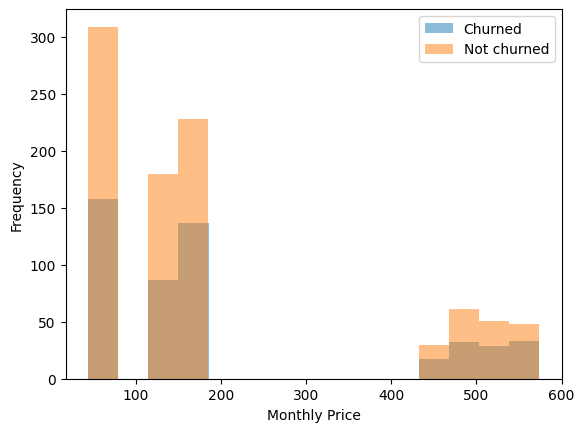

In [ ]:
fig, ax = plt.subplots()
df[df['churned'] == 1]['monthly_price'].plot(
    kind='hist', alpha=0.5, label='Churned', ax=ax, bins=15
)
df[df['churned'] == 0]['monthly_price'].plot(
    kind='hist', alpha=0.5, label='Not churned', ax=ax, bins=15
)
ax.set_xlabel('Monthly Price')
ax.legend()
plt.show()

In [ ]:
res = stats.ttest_ind(
    df_churn["monthly_price"],
    df_no_churn["monthly_price"],
    equal_var=False,
    alternative="greater",
)

print(f"t-statistic: {res.statistic:.4f}")
print(f"p-value: {res.pvalue:.4f}")
print(f"df: {res.df:.2f}")

t-statistic: 0.9559
p-value: 0.1697
df: 986.69


## Had Price Increase Last Quarter vs Churned

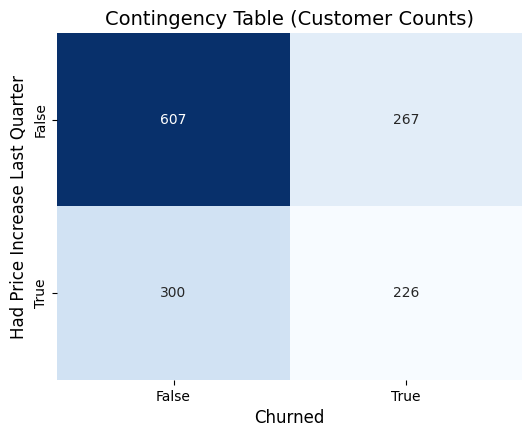

In [ ]:
import seaborn as sns
# Create contingency table of counts
ct = pd.crosstab(df["had_price_increase_last_quarter"], df["churned"])

plt.figure(figsize=(6, 4.5))
sns.heatmap(ct, annot=True, fmt="d", cmap="Blues", cbar=False)

plt.title("Contingency Table (Customer Counts)", fontsize=14)
plt.xlabel("Churned", fontsize=12)
plt.ylabel("Had Price Increase Last Quarter", fontsize=12)
plt.show()

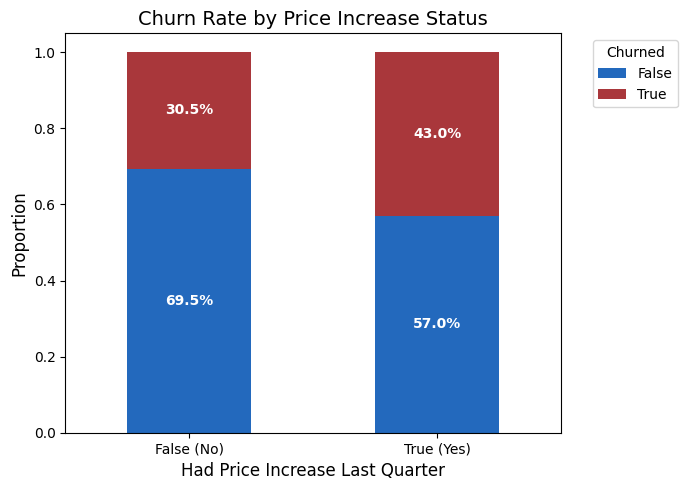

In [ ]:
# 1. Calculate proportion crosstab
crosstab_prop = pd.crosstab(
    df["had_price_increase_last_quarter"], df["churned"], normalize="index"
)

# 2. Plot 100% stacked bar chart
ax = crosstab_prop.plot(
    kind="bar", stacked=True, figsize=(7, 5), colormap="vlag"
)

plt.title("Churn Rate by Price Increase Status", fontsize=14)
plt.xlabel("Had Price Increase Last Quarter", fontsize=12)
plt.ylabel("Proportion", fontsize=12)
plt.xticks([0, 1], ["False (No)", "True (Yes)"], rotation=0)
plt.legend(title="Churned", bbox_to_anchor=(1.05, 1), loc="upper left")

# Annotate percentage values on bars
for p in ax.patches:
    width, height = p.get_width(), p.get_height()
    if height > 0:
        x, y = p.get_xy()
        ax.text(
            x + width / 2,
            y + height / 2,
            f"{height:.1%}",
            ha="center",
            va="center",
            color="white",
            fontweight="bold",
        )

plt.tight_layout()
plt.show()

1. Chi-Square Test

In [ ]:
# 1. Create contingency table
contingency_table = pd.crosstab(
    df["had_price_increase_last_quarter"], df["churned"]
)

# 2. Perform Chi-square test
chi2, p_val, dof, expected = stats.chi2_contingency(contingency_table)

print(f"Chi2 Statistic: {chi2:.4f}")
print(f"p-value:        {p_val:.4f}")

if p_val < 0.05:
    print(
        "Conclusion: Price increase last quarter is significantly associated"
        " with churn!"
    )
else:
    print(
        "Conclusion: Insufficient evidence to show price increase leads to"
        " churn."
    )

Chi2 Statistic: 21.6500
p-value:        0.0000
Conclusion: Price increase last quarter is significantly associated with churn!


In [ ]:
# Pearson correlation coefficient (Phi coefficient)
r, p_val = stats.pearsonr(
    df["had_price_increase_last_quarter"], df["churned"]
)

print(f"Correlation (r): {r:.4f}")  # Positive value means higher churn rate after price increase
print(f"p-value:         {p_val:.4f}")

Correlation (r): 0.1259
p-value:         0.0000


In [ ]:
# Fisher's exact test for Odds Ratio and p-value
odds_ratio, p_val = stats.fisher_exact(contingency_table)

print(f"Odds Ratio: {odds_ratio:.4f}")
print(f"p-value:    {p_val:.4f}")
# Odds Ratio > 1 means customers with price increase last quarter have higher odds of churning

Odds Ratio: 1.7126
p-value:    0.0000


In [ ]:
df_mini = df[['customer_id', 'plan_tier', 'churned']]
df_churn = df_mini[df_mini['churned'] == 1]
df_no_churn = df_mini[df_mini['churned'] == 0]

Contingency Table (Counts):
churned     False  True 
plan_tier               
Basic         309    158
Enterprise    190    111
Pro           408    224

Churn Rates by Plan Tier:
churned        False     True 
plan_tier                     
Basic       0.661670  0.338330
Enterprise  0.631229  0.368771
Pro         0.645570  0.354430

Chi-Square Statistic: 0.7699
p-value:             0.6805
Conclusion: No statistically significant association found between plan tier and churn.


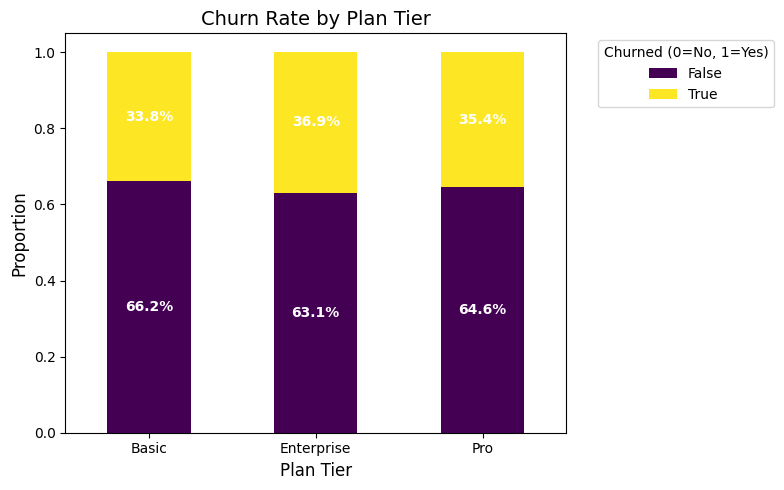

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

# 1. Create a contingency table of counts
contingency_table = pd.crosstab(df["plan_tier"], df["churned"])
print("Contingency Table (Counts):")
print(contingency_table)

# 2. Calculate churn rate by plan tier
churn_rates = pd.crosstab(df["plan_tier"], df["churned"], normalize="index")
print("\nChurn Rates by Plan Tier:")
print(churn_rates)

# 3. Perform Chi-square Test of Independence
chi2, p_val, dof, expected = stats.chi2_contingency(contingency_table)
print(f"\nChi-Square Statistic: {chi2:.4f}")
print(f"p-value:             {p_val:.4f}")

if p_val < 0.05:
    print("Conclusion: There is a statistically significant association between plan tier and churn!")
else:
    print("Conclusion: No statistically significant association found between plan tier and churn.")

# 4. Visualize with a 100% Stacked Bar Chart
ax = churn_rates.plot(kind="bar", stacked=True, figsize=(8, 5), colormap="viridis")
plt.title("Churn Rate by Plan Tier", fontsize=14)
plt.xlabel("Plan Tier", fontsize=12)
plt.ylabel("Proportion", fontsize=12)
plt.xticks(rotation=0)
plt.legend(title="Churned (0=No, 1=Yes)", bbox_to_anchor=(1.05, 1), loc="upper left")

# Annotate percentages on the bars
for p in ax.patches:
    width, height = p.get_width(), p.get_height()
    if height > 0:
        x, y = p.get_xy()
        ax.text(
            x + width / 2,
            y + height / 2,
            f"{height:.1%}",
            ha="center",
            va="center",
            color="white",
            fontweight="bold"
        )

plt.tight_layout()
plt.show()